# 尾部风险平价（TRP）

对应整理稿 4.1 节。尾部风险平价（AllianceBernstein）把风险平价中的「波动率」换成「预期尾部损失」（ETL，即 ES），
使各资产对组合 ES 的贡献相等。整理稿引用的回测（2007–2012，股票、美债、信用债、通胀资产）：
**10% 分位尾部夏普提升 17.3%，5% 分位提升 21.0%，常规夏普提升 7.5%**；并称国内效果一般。

原文的 TRP 还用期权隐含的偏度、波动率来计算「隐含 ETL」。国内大部分资产没有可用的期权，本研究只做基于收益数据的版本：

| 方法 | 让什么相等 | 风险从哪来 |
|---|---|---|
| 风险平价（ERC） | 波动率贡献 | 过去 500 日的协方差 |
| TRP-历史 | 95% ES 贡献 | 过去 500 日的历史收益情景 |
| TRP-条件 | 95% ES 贡献 | 过去 500 日的收益，经 GJR-GARCH 过滤后按明日预测波动率重新缩放（多元过滤历史模拟） |
| **风险平价-条件**（对照） | 波动率贡献 | 与 TRP-条件相同的过滤情景 |

最后一行是关键的对照：如果「风险平价-条件」和「TRP-条件」表现相近，那么改进来自 GARCH 对波动率的跟踪，而不是来自用 ES 代替波动率。

风险预算用凸优化求解：y* = argmin R(y) − Σ ln y_i，w = y*/Σy*（Spinu 2013；Mausser & Romanko 2018）。
避险资产在组合尾部日往往上涨、ES 贡献为负，简单迭代会发散；这个形式在最优点保证各贡献为正且相等。

## 0 · 环境与数据

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%run ../../01_methods.ipynb

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.figsize": (13, 4),
    "axes.unicode_minus": False,
    "font.sans-serif": ["PingFang SC", "Heiti TC", "Arial Unicode MS", "SimHei", "DejaVu Sans"],
})

NAMES = {"沪深300": "沪深300", "中证500": "中证500", "标普500": "标普500", "中债国债总财富": "国债",
         "黄金(GLD×美元兑人民币)": "黄金", "布伦特原油": "原油"}
R = to_returns(load_prices(list(NAMES)).rename(columns=NAMES)).dropna()
print(f"{R.index.min():%Y-%m-%d} ~ {R.index.max():%Y-%m-%d}，{len(R)} 个共同交易日")
R.corr().style.format("{:.2f}")

2005-01-05 ~ 2026-10-12，5008 个共同交易日


,沪深300,中证500,标普500,国债,黄金,原油
沪深300,1.00,0.88,0.12,-0.09,0.06,0.10
中证500,0.88,1.00,0.10,-0.08,0.07,0.09
标普500,0.12,0.10,1.00,-0.04,0.08,0.20
国债,-0.09,-0.08,-0.04,1.00,0.03,-0.05
黄金,0.06,0.07,0.08,0.03,1.00,0.09
原油,0.10,0.09,0.20,-0.05,0.09,1.00


六类资产对应原文的四类：股票（沪深300、中证500、标普500）、国债、通胀资产（黄金、原油）；国内没有与美国信用债对应的长历史免费数据。
美股、黄金、原油与 A 股收盘时间不同，同日相关会被低估；本研究是月度调仓的配置，影响有限。

## 1 · 回测

In [2]:
def tail_sharpe(r, rf=0.02, q=0.95):
    # 原文口径：超额收益 / 月度 ETL。这里年化：年化超额收益 / (月度 95% ES × √12)
    m = (1 + r).resample("ME").prod() - 1
    ann = (1 + r).prod() ** (244 / len(r)) - 1
    return (ann - rf) / (es_hist(m, q) * np.sqrt(12))

def strategies(q=0.95):
    return {
        "等权": equal_weights,
        "风险平价": erc_weights,
        "TRP-历史": lambda W: es_parity_weights(W, q),
        "TRP-条件": lambda W: es_parity_weights(fhs_scenarios(W), q),
        "风险平价-条件": lambda W: erc_weights(fhs_scenarios(W)),
    }

def table(P, Wt, period=slice(None)):
    rows = {}
    for c in P:
        r = P[c].loc[period]
        s = perf_stats(r)
        rows[c] = {"年化收益": s["年化收益"], "年化波动": s["年化波动"], "超额夏普": s["超额夏普"],
                   "尾部夏普(5%)": tail_sharpe(r, q=0.95), "尾部夏普(10%)": tail_sharpe(r, q=0.90),
                   "最大回撤": s["最大回撤"], "月均换手": turnover(Wt[c].loc[period])}
    return pd.DataFrame(rows).T

FMT = {"年化收益": "{:.2%}", "年化波动": "{:.2%}", "超额夏普": "{:.2f}", "尾部夏普(5%)": "{:.2f}",
       "尾部夏普(10%)": "{:.2f}", "最大回撤": "{:.2%}", "月均换手": "{:.1%}"}

P, WT = rolling_backtest(R, strategies(), lookback=500)
print(f"回测区间 {P.index.min():%Y-%m-%d} ~ {P.index.max():%Y-%m-%d}，每月调仓、回看 500 日、不计成本")
full = table(P, WT)
full.style.format(FMT)

回测区间 2007-07-02 ~ 2026-10-12，每月调仓、回看 500 日、不计成本


,年化收益,年化波动,超额夏普,尾部夏普(5%),尾部夏普(10%),最大回撤,月均换手
等权,7.88%,13.85%,0.42,0.17,0.24,-42.58%,0.0%
风险平价,5.49%,3.89%,0.90,0.51,0.70,-8.53%,0.7%
TRP-历史,5.39%,3.63%,0.94,0.54,0.73,-8.00%,1.1%
TRP-条件,5.55%,3.45%,1.03,0.62,0.84,-5.80%,7.6%
风险平价-条件,5.67%,3.63%,1.01,0.60,0.83,-6.13%,7.6%


In [3]:
pd.DataFrame({k: v.mean() for k, v in WT.items()}).style.format("{:.1%}")

,等权,风险平价,TRP-历史,TRP-条件,风险平价-条件
沪深300,16.7%,4.4%,4.0%,3.9%,4.3%
中证500,16.7%,3.8%,3.4%,3.2%,3.7%
标普500,16.7%,7.3%,6.9%,7.5%,7.9%
国债,16.7%,73.2%,75.1%,75.4%,73.0%
黄金,16.7%,8.0%,7.4%,6.7%,7.6%
原油,16.7%,3.4%,3.2%,3.2%,3.4%


In [4]:
base = full.loc["风险平价"]
pd.DataFrame({m: {"超额夏普": full.loc[m, "超额夏普"] / base["超额夏普"] - 1,
                  "尾部夏普(5%)": full.loc[m, "尾部夏普(5%)"] / base["尾部夏普(5%)"] - 1,
                  "尾部夏普(10%)": full.loc[m, "尾部夏普(10%)"] / base["尾部夏普(10%)"] - 1}
              for m in ["TRP-历史", "TRP-条件", "风险平价-条件"]}).T.style.format("{:+.1%}")

,超额夏普,尾部夏普(5%),尾部夏普(10%)
TRP-历史,+4.4%,+6.6%,+4.7%
TRP-条件,+15.0%,+22.2%,+20.8%
风险平价-条件,+12.8%,+17.7%,+18.5%


上表是相对普通风险平价的提升幅度，可与原文的「尾部夏普 +17–21%、夏普 +7.5%」对照。

## 1.1 提升是否显著？改进来自哪里？

分块自助法（20 日一块，2000 次）检验超额夏普差：

In [5]:
pairs = [("TRP-历史", "风险平价", "用 ES 代替波动率（无条件）"),
         ("TRP-条件", "风险平价", "条件 TRP 相对普通风险平价"),
         ("风险平价-条件", "风险平价", "只加 GARCH 波动率调整"),
         ("TRP-条件", "风险平价-条件", "在条件情景上，用 ES 代替波动率")]
rows = {}
for a, b, label in pairs:
    pt, lo, hi, p = block_bootstrap_sharpe_diff(P[a], P[b])
    rows[label] = {"比较": f"{a} − {b}", "超额夏普差": pt, "95% 下限": lo, "95% 上限": hi, "差值≤0 的比例": p}
pd.DataFrame(rows).T.style.format({"超额夏普差": "{:+.3f}", "95% 下限": "{:+.3f}", "95% 上限": "{:+.3f}", "差值≤0 的比例": "{:.0%}"})

,比较,超额夏普差,95% 下限,95% 上限,差值≤0 的比例
用 ES 代替波动率（无条件）,TRP-历史 − 风险平价,+0.037,-0.026,+0.104,12%
条件 TRP 相对普通风险平价,TRP-条件 − 风险平价,+0.126,-0.077,+0.333,11%
只加 GARCH 波动率调整,风险平价-条件 − 风险平价,+0.108,-0.067,+0.289,11%
在条件情景上，用 ES 代替波动率,TRP-条件 − 风险平价-条件,+0.018,-0.056,+0.098,31%


## 1.2 分时期与危机期

2007-07 至 2012-12 大致对应原文的回测区间；之后为原文之外的样本。危机期看区间内的最大回撤。

In [6]:
periods = {"2007-07 – 2012（原文区间）": slice("2007-07-01", "2012-12-31"), "2013 – 2026-10": slice("2013-01-01", None)}
pd.concat({k: table(P, WT, v)[["超额夏普", "尾部夏普(5%)", "最大回撤"]] for k, v in periods.items()}, axis=1).style.format(
    {c: ("{:.2%}" if "回撤" in c[1] else "{:.2f}") for c in pd.MultiIndex.from_product([periods, ["超额夏普", "尾部夏普(5%)", "最大回撤"]])})

In [7]:
crises = {"2008 金融危机": ("2008-01-01", "2008-12-31"), "2015 A股股灾": ("2015-06-01", "2016-02-29"),
          "2020 疫情": ("2020-02-01", "2020-04-30"), "2022 股债双杀": ("2022-01-01", "2022-10-31")}
pd.DataFrame({k: {c: max_drawdown(P[c].loc[a:b]) for c in P} for k, (a, b) in crises.items()}).style.format("{:.2%}")

,2008 金融危机,2015 A股股灾,2020 疫情,2022 股债双杀
等权,-42.58%,-27.94%,-25.99%,-13.09%
风险平价,-6.10%,-8.53%,-5.98%,-2.36%
TRP-历史,-6.42%,-8.00%,-5.31%,-2.20%
TRP-条件,-5.80%,-4.03%,-5.06%,-1.93%
风险平价-条件,-5.70%,-5.24%,-6.13%,-2.15%


## 1.3 稳健性

依次改变：回看 250 / 1000 日；ES 置信水平 99%；只用国内资产（沪深300、中证500、国债、黄金）——
对应整理稿「国内效果一般」的说法。只报告超额夏普与 5% 尾部夏普。

In [8]:
robust = {}
for label, kw, Rx in [("回看 250 日", {"lookback": 250}, R), ("回看 1000 日", {"lookback": 1000}, R),
                      ("ES 99%", {"lookback": 500, "q": 0.99}, R),
                      ("仅国内资产", {"lookback": 500}, R[["沪深300", "中证500", "国债", "黄金"]])]:
    q = kw.pop("q", 0.95)
    Px, Wx = rolling_backtest(Rx, strategies(q), **kw)
    t = table(Px, Wx)
    robust[label] = t["超额夏普"].round(3).astype(str) + " / " + t["尾部夏普(5%)"].round(3).astype(str)
print("每格：超额夏普 / 尾部夏普(5%)")
pd.DataFrame(robust)

每格：超额夏普 / 尾部夏普(5%)


,回看 250 日,回看 1000 日,ES 99%,仅国内资产
等权,0.562 / 0.24,0.485 / 0.23,0.425 / 0.175,0.277 / 0.109
风险平价,0.954 / 0.559,1.007 / 0.618,0.896 / 0.507,1.047 / 0.615
TRP-历史,0.994 / 0.574,1.085 / 0.695,0.796 / 0.431,1.065 / 0.635
TRP-条件,1.121 / 0.779,1.204 / 0.763,0.929 / 0.608,1.135 / 0.643
风险平价-条件,1.058 / 0.696,1.15 / 0.722,1.011 / 0.596,1.089 / 0.611


## 2 · 净值

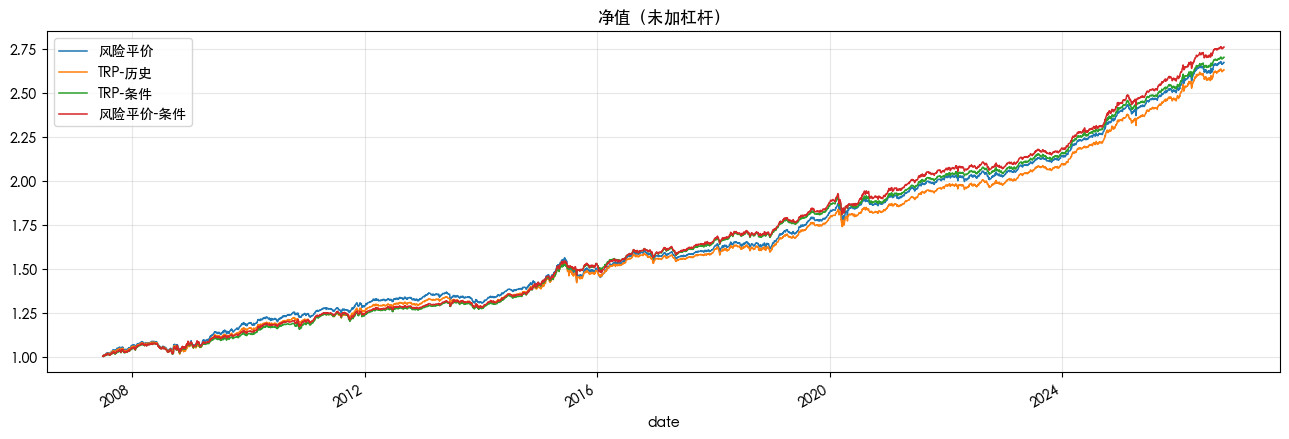

In [9]:
nav = (1 + P[["风险平价", "TRP-历史", "TRP-条件", "风险平价-条件"]]).cumprod()
fig, ax = plt.subplots(figsize=(13, 4.5))
nav.plot(ax=ax, lw=1.1)
ax.set_title("净值（未加杠杆）"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
# 结论

| 问题 | 结论 |
|---|---|
| TRP 是否优于普通风险平价 | **略好，但不显著**。历史 TRP：超额夏普 +4%、尾部夏普 +7%；条件 TRP：+15%、+22%（与原文 +17–21% 同一量级）；所有差异的 95% 区间都包含 0 |
| 改进来自哪里 | **主要来自 GARCH 波动率调整，而不是用 ES 代替波动率**。只做波动率调整的「风险平价-条件」已拿到大部分提升；在同样的条件情景上，ES 比波动率只多出 0.018 的超额夏普（p≈31%） |
| 原文的回测区间（2007–2012） | **TRP 反而略差**：超额夏普 0.77（历史）、0.63（条件），普通风险平价 0.81；提升全部来自 2013 年之后 |
| 稳健性 | ES 取 99% 时历史 TRP 明显变差（500 日里只有 5 个尾部观测）；只用国内资产时与普通风险平价几乎相同，与整理稿「国内效果一般」一致 |
| 危机期 | 条件 TRP 在 2015 年股灾中回撤最小（−4.0%，普通风险平价 −8.5%）；2008 年各方法相近 |

用收益数据估计的尾部风险平价，与普通风险平价的差别主要来自是否跟踪当前波动率；
原文强调的期权隐含 ETL 在国内缺少数据，无法检验。